# Phase B.2 - Ground Truth Dataset Construction
## Objective:

Transform Sen4AgriNet parcel maps into individual training instances suitable for decoder fine-tuning.

Each training sample will contain:

* RGB image
* parcel mask
* parcel centroid
* parcel area

These samples will later be used to fine-tune the SAM2 decoder.

In [1]:
import sys

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
DATA_ROOT = Path(
    "/content/drive/MyDrive/Sen4SAM"
)

PROCESSED = DATA_ROOT / "processed" / "processed"

In [4]:
manifest = pd.read_csv(
    DATA_ROOT / "manifest.csv"
)

manifest = manifest[
    manifest["kept"] == 1
]

print(len(manifest))

888


In [5]:
def load_rgb(patch):

    return np.array(
        Image.open(
            PROCESSED /
            f"{patch}_rgb.png"
        ).convert("RGB")
    )

In [6]:
def load_parcels(patch):

    return np.load(
        PROCESSED /
        f"{patch}_parcels.npy"
    )

In [7]:
def extract_parcels(parcel_map):

    ids = np.unique(parcel_map)

    ids = ids[ids != 0]

    masks = []

    for pid in ids:

        mask = (
            parcel_map == pid
        )

        masks.append(
            (pid,mask)
        )

    return masks

Probamos con un patch

In [8]:
patch = "2019_31UCP_patch_25_23"

img = load_rgb(patch)

parcel_map = load_parcels(patch)

instances = extract_parcels(
    parcel_map
)

In [9]:
print(
    "Número de parcelas:",
    len(instances)
)

Número de parcelas: 218


Visualizamos algunas parcelas

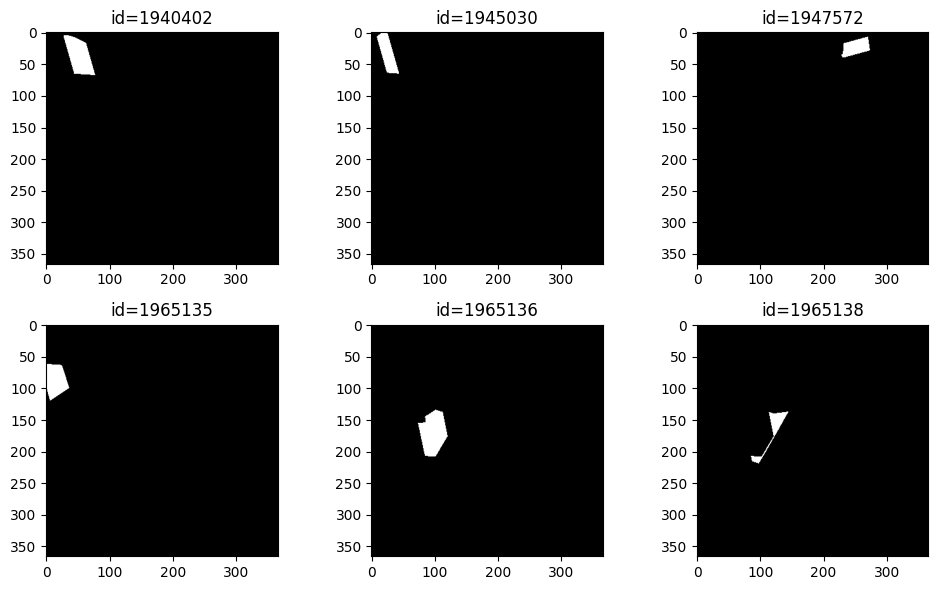

In [10]:
fig,ax = plt.subplots(
    2,
    3,
    figsize=(10,6)
)

for i in range(6):

    pid,mask = instances[i]

    ax.ravel()[i].imshow(
        mask,
        cmap="gray"
    )

    ax.ravel()[i].set_title(
        f"id={pid}"
    )

plt.tight_layout()
plt.show()

Generamos centroides para promps automaticos

In [11]:
def centroid(mask):

    y,x = np.where(mask)

    return (
        float(x.mean()),
        float(y.mean())
    )

In [12]:
for i in range(5):

    pid,mask = instances[i]

    print(
        pid,
        centroid(mask)
    )

1940402 (51.83386411889597, 37.38535031847134)
1945030 (25.59983150800337, 33.09519797809604)
1947572 (250.30299785867237, 23.5203426124197)
1965135 (14.81860465116279, 88.78205980066446)
1965136 (97.68538362623232, 171.57908272610374)


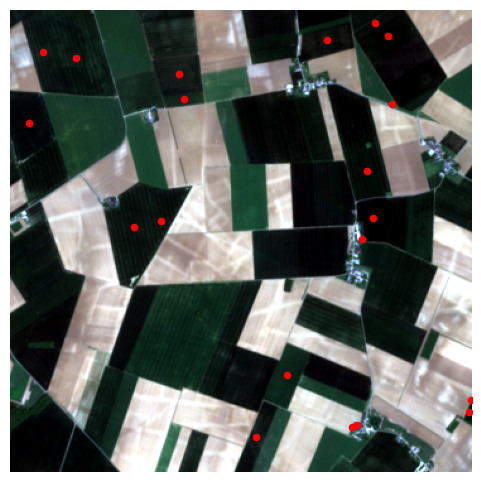

In [13]:
plt.figure(figsize=(6,6))

plt.imshow(img)

for pid,mask in instances[:20]:

    cx,cy = centroid(mask)

    plt.scatter(
        cx,
        cy,
        color="red",
        s=20
    )

plt.axis("off")

plt.show()

Construccion del dataset

In [ ]:
rows = []

# Split por parche (results/split.csv, o copia en Drive: Sen4SAM/split.csv): solo parches de "train".
SPLIT_PATH = next((p for p in [Path.cwd() / "results" / "split.csv", DATA_ROOT / "split.csv"] if p.exists()), None)
assert SPLIT_PATH is not None, "Copia results/split.csv a Drive en Sen4SAM/split.csv"
split = pd.read_csv(SPLIT_PATH)
train_patches = set(split.loc[split["split"] == "train", "patch"])
manifest_train = manifest[manifest["patch"].isin(train_patches)]

subset = manifest_train.sample(
    50,
    random_state=42
)

In [15]:
for _,row in subset.iterrows():

    patch = row["patch"]

    parcel_map = load_parcels(
        patch
    )

    instances = extract_parcels(
        parcel_map
    )

    for pid,mask in instances:

        area = mask.sum()

        if area < 20:
            continue

        cx,cy = centroid(mask)

        rows.append({

            "patch":patch,

            "parcel_id":int(pid),

            "area":int(area),

            "cx":cx,

            "cy":cy

        })

DataFrame

In [16]:
gt_dataset = pd.DataFrame(
    rows
)

gt_dataset.head()

,patch,parcel_id,area,cx,cy
0,2019_31TBF_patch_24_24,1152686,131,78.450382,357.992366
1,2019_31TBF_patch_24_24,1152687,169,51.615385,355.420118
2,2019_31TBF_patch_24_24,1152688,133,66.120301,343.646617
3,2019_31TBF_patch_24_24,1152792,360,97.111111,359.363889
4,2019_31TBF_patch_24_24,1152794,28,100.000000,345.107143


Resumen

In [17]:
gt_dataset.describe()

,parcel_id,area,cx,cy
count,1.053500e+04,10535.000000,10535.000000,10535.000000
mean,4.030124e+06,223.055339,184.235039,182.624047
std,3.388598e+06,348.900875,109.523127,107.897758
min,6.401120e+05,20.000000,0.600000,0.000000
25%,1.020492e+06,50.000000,87.288173,90.624852
50%,2.389664e+06,108.000000,186.654676,182.365854
75%,7.833644e+06,248.000000,279.597154,276.670323
max,9.955527e+06,7391.000000,364.619048,364.703704


Distribución de áreas

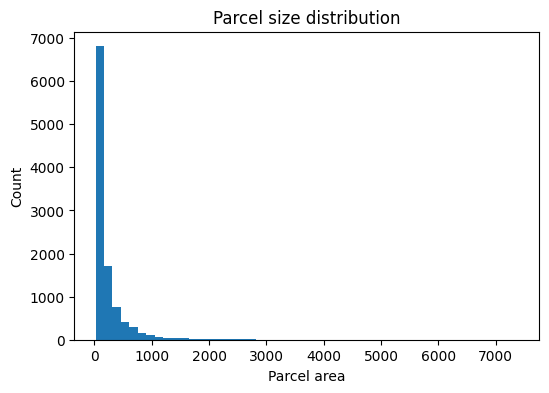

In [18]:
plt.figure(figsize=(6,4))

plt.hist(
    gt_dataset["area"],
    bins=50
)

plt.xlabel(
    "Parcel area"
)

plt.ylabel(
    "Count"
)

plt.title(
    "Parcel size distribution"
)

plt.show()

Guardar dataset

In [19]:
gt_dataset.to_csv(

    DATA_ROOT /
    "gt_parcel_dataset.csv",

    index=False
)